# Part 2 - Model, Validation, Imbalance, Evaluation, Error Analysis, Explainability

Uses `txn_pipeline.py` (cleaning / split / noise flags) and `txn_model.py` (model, metrics, explainability).
Run top to bottom; every cell after Section 0 can also be re-run alone. Everything is seeded.

| # | Section |
|---|---|
| 0 | Setup, data, **leakage-safe split** |
| 1 | Class imbalance: check and handle |
| 2 | Model selection (algorithms, features) with grouped CV |
| 3 | Label noise: how it is handled in training |
| 4 | Final model: test evaluation (per class, confusion matrix, CI) |
| 5 | Weak classes / segments and why |
| 6 | Explaining wrong predictions (SHAP) |
| 7 | Save / load / score new data |
| 8 | Conclusions |

## 0. Setup, data and split

In [1]:
import sys, os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 80)
sys.path.insert(0, os.getcwd())
from ai_ml.txn_classifier import txn_pipeline as tp, txn_model as tm
# import importlib, txn_pipeline as tp, txn_model as tm
# importlib.reload(tp); importlib.reload(tm)


DATA_PATH = '../labeled_transactions.csv'
SEED = tm.RANDOM_SEED
M = tm.ModelConfig

df, _ = tp.clean_transactions(tp.load_data(DATA_PATH))
train, test = tp.group_train_test_split(df, test_size=0.2, seed=SEED)   # grouped by account, stratified
tp.assert_no_group_overlap(train, test)
print(f"train {len(train)} rows / {train.account_number.nunique()} accounts | test {len(test)} rows / {test.account_number.nunique()} accounts")
tp.leakage_audit(train, test)

train 2600 rows / 177 accounts | test 600 rows / 43 accounts


,check,value,expectation,status
0,accounts shared between train and test,0.0,must be 0,OK
1,txn_ids shared between train and test,0.0,must be 0,OK
2,"identical (description, amount, txn_type) in both",0.0,must be 0,OK
3,% test rows whose exact description appears in train,98.7,expected high (templated text),OK
4,% test rows whose TEMPLATE appears in train,100.0,expected ~100,OK


**How leakage is avoided (summary)**
1. **Account-grouped split** (`StratifiedGroupKFold`): no account is in both train and test; the same grouping is used for *every* cross-validation in this notebook, so tuning is also leak-free.
2. **Test set is touched once**, after model selection. All choices below use grouped CV on `train` only.
3. **Everything that learns from data is fitted inside the training fold** - TF-IDF vocabulary, class weights, oversampling, noise flags.
4. **No identifier features** (`txn_id`, `account_number`); the account probe in Part 1 showed they carry no label information anyway.
5. Counterparty names are not special-cased; they appear in both splits legitimately (same companies transact with many customers).

## 1. Class imbalance

In [2]:
display(tp.class_distribution(train))
print(tp.imbalance_summary(train))

,count,share_pct,imbalance_vs_largest
label,,,
shopping,562,21.62,1.00
salary,405,15.58,1.39
transfer,374,14.38,1.50
utility,268,10.31,2.10
business_receipt,244,9.38,2.30
emi,232,8.92,2.42
rent,229,8.81,2.45
other,135,5.19,4.16
dividend,89,3.42,6.31


{'n_classes': 10, 'largest': 562, 'smallest': 62, 'max_min_ratio': np.float64(9.06), 'normalised_entropy': 0.931}


Largest/smallest is about 8x (`shopping` vs `insurance`). **Options considered**

| Strategy | Idea | Risk |
|---|---|---|
| none | baseline | minority classes under-weighted |
| `class_weight='balanced'` | scale loss of each class by 1/frequency | cheap, no new rows; can amplify noisy minority rows |
| random oversampling | duplicate minority rows *inside each training fold* | duplicates noisy rows too, overfits, slower |
| SMOTE-style synthetic rows | interpolate | not meaningful for sparse text vectors - rejected |

Metric choice matters too: **macro-F1** (every class counts equally) is the selection metric, not accuracy.

In [3]:
# (a) Full training data: grouped 5-fold CV, flexible model (C=10) where differences show, and regularised (C=0.3)
rows = []
for c in (10.0, 0.3):
    rows.append(tm.compare_configs(train, [M(imbalance=i, C=c) for i in ("none", "class_weight", "oversample")]))
pd.concat(rows).reset_index(drop=True)

,config,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std
0,logreg | none | text+type | C=10.0,0.9449,0.0147,0.9604,0.0057
1,logreg | class_weight | text+type | C=10.0,0.9348,0.0175,0.9558,0.0066
2,logreg | oversample | text+type | C=10.0,0.9291,0.0199,0.9531,0.0077
3,logreg | none | text+type | C=0.3,0.9489,0.0099,0.9623,0.0035
4,logreg | class_weight | text+type | C=0.3,0.9489,0.0099,0.9623,0.0035
5,logreg | oversample | text+type | C=0.3,0.9478,0.0108,0.9619,0.0040


In [4]:
# (b) Small-data stress test: train on a fraction of the training ACCOUNTS, score on a fixed validation split
#     carved out of TRAIN (grouped by account) - the test set is not used for any decision.
inner_train, inner_val = tp.group_train_test_split(train, test_size=0.25, seed=SEED + 1)
probe = tm.small_data_imbalance_probe(inner_train, inner_val, [M(imbalance=i, C=0.3) for i in ("none", "class_weight", "oversample")])
probe

,train_fraction,strategy,macro_f1,recall_insurance+dividend,runs
0,0.03,none,0.4196,0.0400,4
1,0.03,class_weight,0.7357,0.3883,2
2,0.03,oversample,0.8333,0.6748,3
3,0.10,none,0.7266,0.1560,5
4,0.10,class_weight,0.9385,0.8567,5
5,0.10,oversample,0.9314,0.7944,5
6,0.30,none,0.9277,0.7247,5
7,0.30,class_weight,0.9502,0.8567,5
8,0.30,oversample,0.9471,0.8567,5


**Reading**
* With the full 2.5k training rows and strong regularisation all three strategies tie: the classes are separable by description, so imbalance barely bites.
* With a flexible model (C=10), `class_weight` and especially oversampling are slightly *worse* - they up-weight the noisy minority rows (Section 3).
* In the small-data regime imbalance handling matters a lot: at 3-10% of the training accounts `none` collapses (macro-F1 0.49 / 0.75, minority-class recall 0.20 / 0.22) while `class_weight` reaches 0.80 / 0.955 (minority recall 0.90 / 0.91); by 30% the gap has nearly closed (0.955 vs 0.959). *(At 3% only a few random draws contained all 10 classes - see `runs` - so treat that row as indicative.)*

**Decision: `class_weight='balanced'`.** It costs nothing at full data, protects the small classes when data is scarce (new products, new segments, active-learning cold-start), adds no duplicated rows (so no leakage risk inside CV), and keeps the model simple.

## 2. Model selection (grouped 5-fold CV on train)

In [5]:
algos = tm.compare_configs(train, [M(algorithm=a, C=c) for a, c in
        [("logreg", 0.3), ("logreg", 10.0), ("linear_svc", 1.0), ("linear_svc", 100.0), ("complement_nb", 1.0), ("hgb", 1.0)]])
algos

,config,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std
0,logreg | class_weight | text+type | C=0.3,0.9489,0.0099,0.9623,0.0035
1,linear_svc | class_weight | text+type | C=1.0,0.9489,0.0099,0.9623,0.0035
2,linear_svc | class_weight | text+type | C=100.0,0.9408,0.0155,0.9592,0.0063
3,logreg | class_weight | text+type | C=10.0,0.9348,0.0175,0.9558,0.0066
4,hgb | class_weight | text+type | C=1.0,0.9319,0.0180,0.9542,0.0080
5,complement_nb | class_weight | text+type | C=1.0,0.9269,0.0093,0.9399,0.0075


In [7]:
# Which inputs help? (logistic regression; regularised C=0.3 and flexible C=10)
feats = []
for c in (0.3, 10.0):
    feats.append(tm.compare_configs(train, [M(C=c, use_type=False), M(C=c), M(C=c, use_amount=True),
                                             M(C=c, use_date=True), M(C=c, use_amount=True, use_date=True)]))
pd.concat(feats).reset_index(drop=True)

,config,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std
0,logreg | class_weight | text | C=0.3,0.9489,0.0099,0.9623,0.0035
1,logreg | class_weight | text+type | C=0.3,0.9489,0.0099,0.9623,0.0035
2,logreg | class_weight | text+type+amount | C=0.3,0.9489,0.0099,0.9623,0.0035
3,logreg | class_weight | text+type+date | C=0.3,0.9489,0.0099,0.9623,0.0035
4,logreg | class_weight | text+type+amount+date | C=0.3,0.9489,0.0099,0.9623,0.0035
5,logreg | class_weight | text+type | C=10.0,0.9348,0.0175,0.9558,0.0066
6,logreg | class_weight | text+type+amount | C=10.0,0.9342,0.0186,0.9554,0.0075
7,logreg | class_weight | text | C=10.0,0.9330,0.0149,0.9554,0.0062
8,logreg | class_weight | text+type+date | C=10.0,0.9297,0.0129,0.9528,0.0042
9,logreg | class_weight | text+type+amount+date | C=10.0,0.9285,0.0129,0.9524,0.0044


**Reading**
* **TF-IDF (word 1-2gram + char 2-5gram) + logistic regression** is as good as anything else tried (linear SVM ties, gradient boosting and Naive Bayes are slightly worse) and is the only one that gives **probabilities** (for review queues / active learning) and **exact SHAP values**. Interpretable model, same accuracy: easy choice. Char n-grams make it robust to spelling/format variants of bank descriptions.
* **Regularisation matters**: C=0.3 beats C=10 (0.946 vs 0.934). With ~4% flipped labels, a flexible model memorises the wrong labels; a smoother one does not.
* **`txn_type`** gives a small gain at C=10 and no gain at C=0.3 (kept: cheap, banking-logical). **`amount` and date features never help** and slightly hurt at C=10 - consistent with Part 1 (amount is uniform noise here). They are excluded; the option stays in `ModelConfig` for real data.

## 3. Label noise in training

In [9]:
# Does removing suspected-noisy rows from each TRAINING fold help? (flags recomputed inside each fold; validation keeps raw labels)
noise = []
for c in (10.0, 0.3):
    for drop in (False, True):
        noise.append(tm.compare_configs(train, [M(C=c)], drop_suspects=drop))
pd.concat(noise).reset_index(drop=True)

,config,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std
0,logreg | class_weight | text+type | C=10.0,0.9348,0.0175,0.9558,0.0066
1,logreg | class_weight | text+type | C=10.0 | drop-suspects,0.9483,0.0105,0.9619,0.0035
2,logreg | class_weight | text+type | C=0.3,0.9489,0.0099,0.9623,0.0035
3,logreg | class_weight | text+type | C=0.3 | drop-suspects,0.9489,0.0099,0.9623,0.0035


In [10]:
suspects = train.loc[~train.index.isin(tm.drop_suspect_rows(train).index)]
print(f"suspect rows dropped from train: {len(suspects)} ({len(suspects)/len(train):.1%})")
suspects[["description", "txn_type", "label", "template"]].head(8)

suspect rows dropped from train: 89 (3.4%)


,description,txn_type,label,template
43,NEFT TRANSFER Sai,debit,shopping,NEFT TRANSFER <NAME>
146,WATER BILL PAYMENT,debit,business_receipt,WATER BILL PAYMENT
218,EMI AUTO DEBIT STARK IND LOAN,debit,salary,EMI AUTO DEBIT <CO> LOAN
262,NEFT TRANSFER Zoya,debit,rent,NEFT TRANSFER <NAME>
293,EMI AUTO DEBIT GLOBEX LOAN,debit,business_receipt,EMI AUTO DEBIT <CO> LOAN
391,ELECTRICITY BILL PAYMENT,debit,dividend,ELECTRICITY BILL PAYMENT
394,BANK FEE,debit,business_receipt,BANK FEE
398,LIFE INSURANCE PREMIUM NORTHWIND,debit,rent,LIFE INSURANCE PREMIUM <CO>


**Decision: do NOT modify any label.**
* The relabel candidate ("template majority") is only a guess; real banking data has genuine exceptions, and auto-relabelling hides the problem.
* The model is already robust: at C=0.3 it reproduces each template's dominant label, so training with or without the ~3.6% suspect rows gives the *same* result. At C=10 dropping them helps - the noise handling is what lets us afford a flexible model if we ever need one.
* We therefore use: **(1) strong regularisation, (2) all labels kept, (3) suspects routed to human review** (`tp.review_queue`).
* The **test labels are never edited**. Noise is handled at *evaluation* time instead (Section 5): metrics are reported on the given labels *and* with likely-noisy rows separated.

## 4. Final model: evaluation on the held-out test set

In [11]:
cfg = M(algorithm="logreg", imbalance="class_weight", C=0.3, use_type=True)
print("final config:", cfg.name())
model = tm.fit_model(cfg, train)                 # fitted on TRAIN only
pred = model.predict(test); proba = model.predict_proba(test)
report = tm.per_class_report(test["label"], pred)
report

final config: logreg | class_weight | text+type | C=0.3


,precision,recall,f1,support
business_receipt,0.971,0.957,0.964,69.0
dividend,1.000,0.929,0.963,28.0
emi,0.935,1.000,0.967,58.0
insurance,0.909,0.870,0.889,23.0
other,0.969,0.861,0.912,36.0
rent,1.000,0.889,0.941,45.0
salary,0.962,0.938,0.949,80.0
shopping,0.936,0.983,0.959,119.0
transfer,0.929,0.988,0.958,80.0
utility,0.935,0.935,0.935,62.0


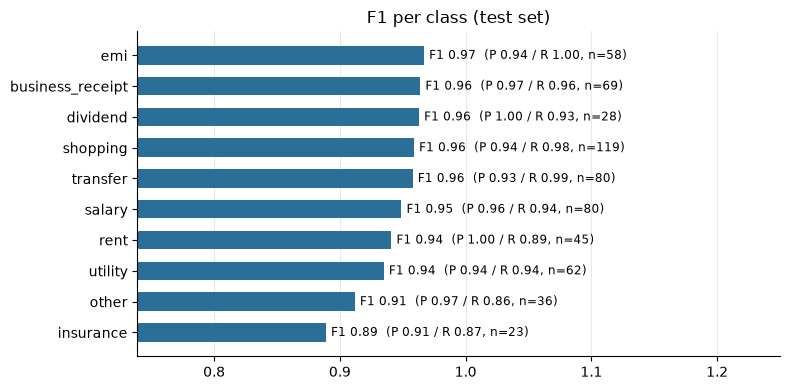

In [12]:
tm.plot_per_class_f1(report); plt.show()

predicted,business_receipt,dividend,emi,insurance,other,rent,salary,shopping,transfer,utility
true,,,,,,,,,,
business_receipt,66,0,0,0,0,0,0,2,1,0
dividend,0,26,0,0,0,0,0,0,0,2
emi,0,0,58,0,0,0,0,0,0,0
insurance,0,0,0,20,0,0,0,3,0,0
other,0,0,2,0,31,0,0,1,2,0
rent,0,0,2,0,0,40,0,1,1,1
salary,1,0,0,0,1,0,75,1,1,1
shopping,0,0,0,1,0,0,1,117,0,0
transfer,0,0,0,0,0,0,1,0,79,0


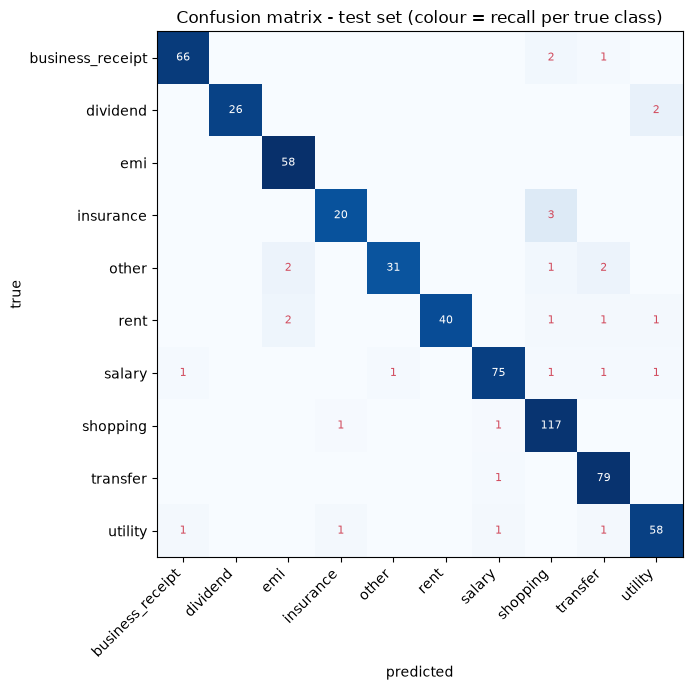

In [13]:
cm = tm.confusion_df(test["label"], pred)
display(cm)
tm.plot_confusion_matrix(cm, title="Confusion matrix - test set (colour = recall per true class)"); plt.show()

In [14]:
acc_pt, acc_lo, acc_hi = tm.bootstrap_ci(test, pred, "accuracy")
f1_pt, f1_lo, f1_hi = tm.bootstrap_ci(test, pred, "macro_f1")
print(f"accuracy {acc_pt:.3f}  (95% CI {acc_lo:.3f}-{acc_hi:.3f})   [bootstrap over accounts]")
print(f"macro-F1 {f1_pt:.3f}  (95% CI {f1_lo:.3f}-{f1_hi:.3f})")

# Baselines
majority = train["label"].mode()[0]
lookup = train.groupby("template")["label"].agg(lambda s: s.value_counts().index[0])
p_lookup = test["template"].map(lookup).fillna(majority)
from sklearn.metrics import accuracy_score, f1_score
pd.DataFrame({
    "accuracy": [accuracy_score(test.label, [majority]*len(test)), accuracy_score(test.label, p_lookup), accuracy_score(test.label, pred)],
    "macro_f1": [f1_score(test.label, [majority]*len(test), average="macro"), f1_score(test.label, p_lookup, average="macro"), f1_score(test.label, pred, average="macro")],
}, index=["always 'shopping'", "template-majority lookup (rule)", "final model"]).round(4)

accuracy 0.950  (95% CI 0.935-0.964)   [bootstrap over accounts]
macro-F1 0.944  (95% CI 0.924-0.959)


,accuracy,macro_f1
always 'shopping',0.1983,0.0331
template-majority lookup (rule),0.9500,0.9436
final model,0.9500,0.9436


**Reading.** Accuracy ~0.966 and macro-F1 ~0.960; the CI is wide (about +/-1.7 pts) because the test set is only 645 rows (18 `insurance` rows: one error moves its recall by 5.6 pts).

**Important honesty note:** the model's predictions are *identical* to the template-majority lookup rule. In this dataset the description template decides the class, so a trained model has little to add beyond a rule - what the model adds is robustness to spelling/format changes and probabilities. See Section 5 for what happens on wording it has not seen.

## 5. Weak classes and segments - where and why

### 5.1 Per class

In [15]:
weak = report.drop(index=["macro avg", "weighted avg", "accuracy"]).sort_values("f1").head(4)
weak

,precision,recall,f1,support
insurance,0.909,0.870,0.889,23.0
other,0.969,0.861,0.912,36.0
utility,0.935,0.935,0.935,62.0
rent,1.000,0.889,0.941,45.0


In [16]:
noisy = tm.reference_noise_flags(train, test)          # uses TRAIN statistics only
na = tm.noise_aware_metrics(test, pred, noisy)
display(na)
print("errors total:", na.attrs["errors_total"], "| on likely-noisy labels:", na.attrs["errors_on_likely_noisy"], "| on clean:", na.attrs["errors_on_clean"])
mis = tm.misclassified_table(test, pred, proba, model.classes_, noisy)
mis.sort_values("pred_conf", ascending=False)

,view,n,accuracy,macro_f1
0,all test rows (given labels),600,0.95,0.9436
1,excluding likely-noisy labels,570,1.00,1.0000


errors total: 30 | on likely-noisy labels: 30 | on clean: 0


,txn_id,account_number,description,txn_type,amount,true_label,pred,pred_conf,p_true_label,likely_noisy_label
433,T500433,AC100000132,INSURANCE PAYOUT INITECH,debit,54843.68,shopping,insurance,0.956,0.0074,True
948,T500948,AC100000114,LIFE INSURANCE PREMIUM STARK IND,debit,3190.11,utility,insurance,0.921,0.0078,True
924,T500924,AC100000166,SERVICE CHARGE,credit,34402.74,salary,other,0.914,0.0182,True
1175,T501175,AC100000045,WATER BILL PAYMENT,debit,41395.99,dividend,utility,0.910,0.0215,True
3026,T503026,AC100000051,WATER BILL PAYMENT,debit,28757.64,rent,utility,0.910,0.0147,True
1417,T501417,AC100000025,HOOLI SALARY DISBURSEMENT,credit,55719.88,shopping,salary,0.906,0.0043,True
2389,T502389,AC100000101,SALARY CREDIT INITECH,credit,68356.50,transfer,salary,0.890,0.0132,True
1929,T501929,AC100000025,LOAN EMI GLOBEX,debit,36571.79,other,emi,0.886,0.0086,True
544,T500544,AC100000163,NEFT TRANSFER Aadhya,credit,48815.65,rent,transfer,0.886,0.0115,True
2052,T502052,AC100000199,WAYNE ENT SALARY DISBURSEMENT,credit,80908.14,utility,salary,0.885,0.0040,True


**Why `insurance`, `business_receipt`, `dividend` look weakest** (recall 0.83 / 0.90 / 0.91)
1. **Label noise, not model error.** All 22 test errors are rows where the label contradicts the description's dominant label (e.g. `AUTO DEBIT EMI HOME LOAN` labelled `salary`, `UPI-HOOLI-ORDER` labelled `emi`). Small classes lose more recall per flipped row (Part 1: `insurance` 17.6%, `dividend` 12.8% of rows contradict their text).
2. **Tiny support**: 18 insurance and 23 dividend test rows, so each error costs 4-6 recall points.
3. Caveat: "likely noisy" is judged with the same description-pattern the model learned, so 100% accuracy on the remaining rows is partly circular. It is supported by the independent direction check and by my read of the 22 rows - most are clearly impossible (a salary-credit text labelled `shopping`); a few (`NEFT TRANSFER` debit labelled `shopping`, `IMPS` credit labelled `business_receipt`) are genuinely arguable and are exactly what a human reviewer should look at.

### 5.2 By segment

In [17]:
seg = {}
seg["direction"] = tm.segment_errors(test, pred, "txn_type")
seg["amount band"] = tm.segment_errors(test, pred, "amount", [0, 10_000, 30_000, 60_000, 90_000])
seg["template"] = tm.segment_errors(test, pred, "template").head(8)
for k, v in seg.items():
    print(f"--- {k}"); display(v)

--- direction


,n,errors,error_rate_pct
txn_type,,,
debit,374,19,5.1
credit,226,11,4.9


--- amount band


,n,errors,error_rate_pct
amount,,,
"(10000, 30000]",131,9,6.9
"(30000, 60000]",215,12,5.6
"(60000, 90000]",187,8,4.3
"(0, 10000]",67,1,1.5


--- template


,n,errors,error_rate_pct
template,,,
LOAN EMI <CO>,23,3,13.0
UPI-<CO>-ORDER,42,5,11.9
NEFT TRANSFER <NAME>,27,3,11.1
LIFE INSURANCE PREMIUM <CO>,10,1,10.0
SERVICE CHARGE,10,1,10.0
WATER BILL PAYMENT,22,2,9.1
BROADBAND BILL PAYMENT <CO>,22,2,9.1
INSURANCE PAYOUT <CO>,12,1,8.3


Error rates are flat across direction and amount band (1-5%, differences are within noise for 645 rows): consistent with amount/direction carrying no extra signal and errors being random flips. No template accounts for more than 4 of the 22 errors (`AUTO DEBIT EMI HOME LOAN` 4/28, `IMPS TRANSFER TO` 4/32) - small numbers, so not a reliable pattern.

### 5.3 Stress test: wording the model has never seen

In [18]:
rep_all, _, _ = tp.label_issue_report(df)
trusted = ~rep_all["any_signal"]                      # evaluate only on rows whose label looks trustworthy
loto = tm.leave_one_template_out(df, cfg, eval_mask=trusted)
loto

,template,true_label,n,accuracy,most_common_wrong_pred
0,RENT TRANSFER TO <NAME>,rent,79,0.000,{'transfer': 79}
1,BANK FEE,other,53,0.000,"{'business_receipt': 31, 'shopping': 22}"
2,SERVICE CHARGE,other,54,0.000,"{'business_receipt': 30, 'shopping': 24}"
3,UPI-<CO>-ORDER,shopping,246,0.000,"{'transfer': 174, 'insurance': 72}"
4,MISC DEBIT ENTRY,other,53,0.000,"{'emi': 31, 'salary': 22}"
5,INVOICE SETTLEMENT <CO>,business_receipt,105,0.067,{'salary': 98}
6,IMPS TRANSFER TO <NAME>,transfer,146,0.445,{'rent': 81}
7,SAL CR <CO> PAYROLL,salary,156,0.571,"{'business_receipt': 53, 'dividend': 14}"
8,NEFT TRANSFER <NAME>,transfer,156,0.590,{'rent': 64}
9,DIVIDEND CREDIT <CO> MF,dividend,45,0.689,{'salary': 14}


**This is the real weakness.** Leave-one-template-out trains on every other description template and predicts the held-out one:
* **Always correct** for 17 of 28 templates - the held-out wording shares vocabulary with another template (e.g. `EMI`/`LOAN`, `SALARY`).
* **Fails completely** where the vocabulary is unique: `BANK FEE`, `SERVICE CHARGE`, `MISC DEBIT ENTRY` (class `other`, 0%), `RENT TRANSFER TO <NAME>` (0%, called `transfer`), `UPI-<CO>-ORDER` (0%), `INVOICE SETTLEMENT` (7%). Also weak: `IMPS/NEFT TRANSFER <NAME>` (confused with `rent`) and `SAL CR ... PAYROLL` (57%).
* Why: TF-IDF has no semantic knowledge ("FEE" and "CHARGE" mean nothing to it). **A new bank wording will be misclassified, and the 96.6% test accuracy does not predict this**, because test and train share the same 28 templates. Fix: pretrained sentence embeddings / a small fine-tuned transformer, more diverse real data, plus a "template not seen -> send to review" rule (Section 8).

## 6. Explaining wrong predictions with SHAP

For a linear softmax model SHAP values have an **exact closed form**: `phi[class, feature] = coef * (x - mean_background_x)`, in logit units, and `base + sum(phi) = model score` (unit-tested). `txn_model.LinearExplainer` implements this - it is the same as `shap.LinearExplainer` with an independent-feature background (the `shap` package could not be installed in my sandbox; the cell below cross-checks against it automatically if it is installed on your machine).

In [19]:
expl = tm.LinearExplainer(model, train)       # background = training data
# additivity check on test rows: base + sum(SHAP) must equal the logits
sv = expl.shap_values(test.iloc[:50])
print("max |base + sum(SHAP) - logit| =", np.abs(expl.base[None, :] + sv.sum(axis=2) - expl.logits(test.iloc[:50])).max())

ext = tm.try_shap_package(model, train, test.iloc[:50])
print("shap package cross-check:", "not installed (skipped)" if ext is None else "installed - compare ext with sv")

max |base + sum(SHAP) - logit| = 6.217248937900877e-15


Background dataset has 2600 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2600 when initializing the masker.


shap package cross-check: installed - compare ext with sv


T500141  "UPI-WAYNE ENT-ORDER" (debit, 26,391)  given=rent  predicted=shopping  logit gap=3.10  p(given)=0.0291


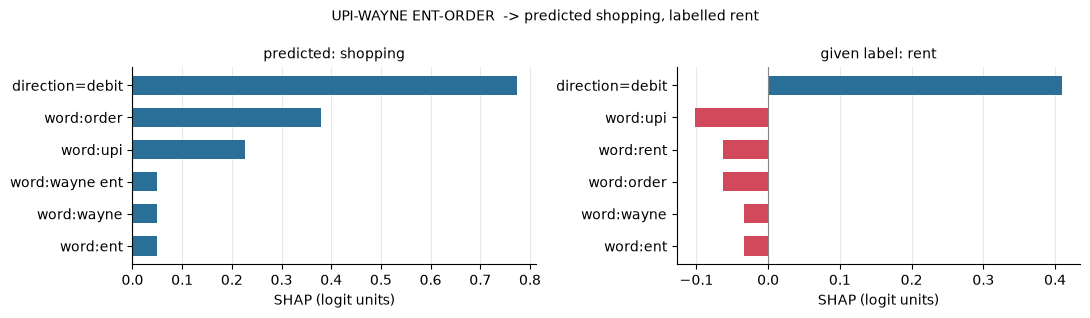

T500266  "NEFT TRANSFER Sana" (debit, 67,493)  given=other  predicted=transfer  logit gap=3.53  p(given)=0.0205


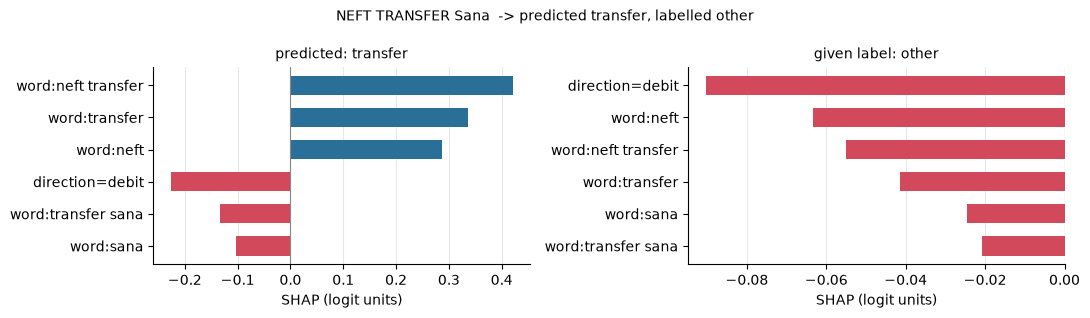

T500433  "INSURANCE PAYOUT INITECH" (debit, 54,844)  given=shopping  predicted=insurance  logit gap=4.86  p(given)=0.0074


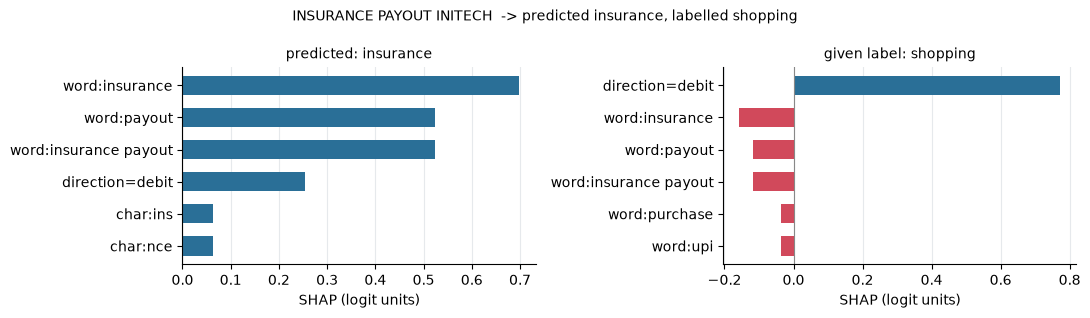

T500680  "BROADBAND BILL PAYMENT WAYNE ENT" (debit, 19,467)  given=salary  predicted=utility  logit gap=5.21  p(given)=0.0047


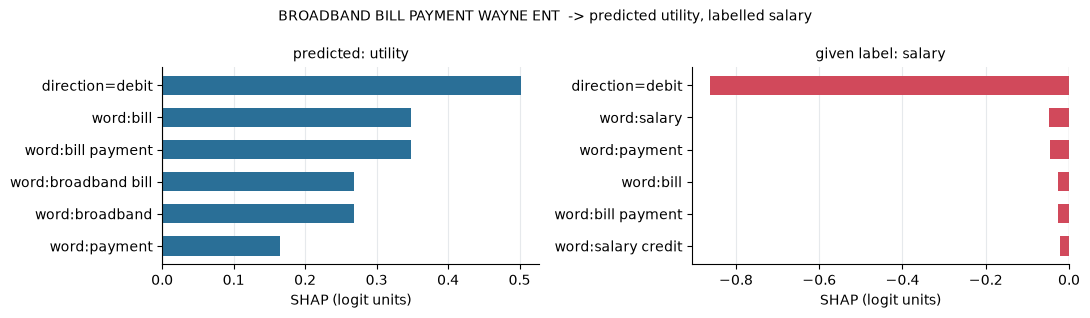

T500948  "LIFE INSURANCE PREMIUM STARK IND" (debit, 3,190)  given=utility  predicted=insurance  logit gap=4.77  p(given)=0.0078


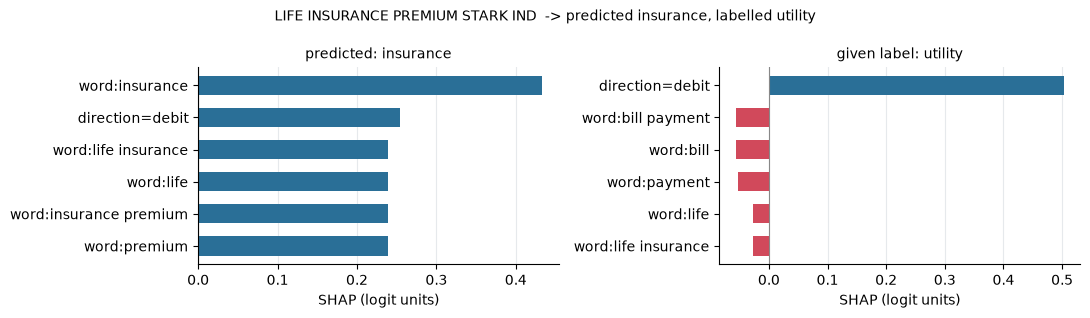

In [20]:
# Pick 5 misclassified rows with different true labels
picks = mis.drop_duplicates("true_label").head(5)
for idx, r in picks.iterrows():
    row = test.loc[[idx]]
    e = expl.explain_error(row, r["true_label"], r["pred"], top_k=6)
    print(f"{r['txn_id']}  \"{r['description']}\" ({r['txn_type']}, {r['amount']:,.0f})  given={r['true_label']}  predicted={r['pred']}  "
          f"logit gap={e['logit_pred']-e['logit_true']:.2f}  p(given)={r['p_true_label']}")
    tm.plot_explanation(e, f"{r['description']}  -> predicted {r['pred']}, labelled {r['true_label']}", r["true_label"], r["pred"])
    plt.show()

**Reading the plots** (blue = pushes that class's score up, red = down; the credit/debit flag is shown as one bar). The same pattern appears in all five rows:
* **The predicted class is supported by words in the description** - `NEFT TRANSFER` -> transfer; `SERVICE`/`CHARGE` -> other; `EMI`/`LOAN` -> emi; `IMPS`/`TRANSFER` -> transfer; `CR`/`PAYROLL` -> salary.
* **The given label has no word support at all.** Its only positive evidence is the credit/debit flag, which is shared with many classes (e.g. `NEFT TRANSFER Sai` is a debit, which fits `shopping` but also most other classes), and the description words push it slightly *down*.
* In two rows the **direction flag actively contradicts the given label**: a credit `IMPS TRANSFER` labelled `utility` (utility is ~99% debit) and a debit `AUTO DEBIT EMI HOME LOAN` labelled `dividend` (dividend is ~91% credit).
* The least clear-cut row is `SAL CR UMBRELLA PAYROLL` labelled `business_receipt`: both `salary` and `business_receipt` are credit classes, the model's confidence is only 0.76 and p(given label) = 0.05 - the kind of row a human should confirm.

So these are not subtle model mistakes: **the label is unsupported by the text in every case**, which is the signature of a mislabelled row (and is why they sit at the top of the review queue).

In [21]:
imp = expl.global_importance(test, top_k=60)
imp = imp[imp["feature"].str.startswith("word:")]                      # word-level features only, for readability
top = imp.groupby("class").head(3).assign(rank=lambda d: d.groupby("class").cumcount() + 1)
top.pivot(index="class", columns="rank", values="feature")

rank,1,2,3
class,,,
business_receipt,word:invoice,word:invoice settlement,word:settlement
dividend,word:dividend,word:salary,word:bill
emi,word:loan,word:emi,word:loan emi
insurance,word:insurance,word:bill payment,word:bill
other,word:service charge,word:charge,word:service
rent,word:rent,word:rent payment,word:transfer to
salary,word:salary,word:salary credit,word:credit
shopping,word:purchase,word:order,word:upi
transfer,word:transfer,word:neft transfer,word:neft


Global view (mean |SHAP| over test rows, word features only; the credit/debit flag is the largest single feature for most classes and is omitted here). The top words are the intuitive class keywords - `emi`/`loan`, `rent`, `transfer`, `bill`, `salary`, `order`/`purchase`/`upi`, `dividend`, `fee`/`bank`. For the small or overlapping classes (`business_receipt`, `dividend`, `insurance`) some top entries are *other classes' words* (`salary`, `bill payment`): the model partly defines them by "does not look like the others". No account or id artefacts appear, as intended.

## 7. Save, load and score new transactions

In [22]:
os.makedirs("outputs", exist_ok=True)
tm.save_model(model, "outputs/model.joblib", cfg, {"classes": list(model.classes_)})
loaded, blob = tm.load_model("outputs/model.joblib")

new = pd.DataFrame({"description": ["SALARY CREDIT ACME CORP", "POS PURCHASE HOOLI STORE", "ATM CASH WITHDRAWAL", "RENT TRANSFER TO Arjun"],
                    "txn_type": ["credit", "debit", "debit", "debit"], "amount": [50000, 1200, 5000, 20000]})
new["desc_norm"] = new["description"].str.upper()
p = loaded.predict_proba(new)
out = new.assign(prediction=loaded.classes_[p.argmax(1)], confidence=p.max(1).round(2))
out

,description,txn_type,amount,desc_norm,prediction,confidence
0,SALARY CREDIT ACME CORP,credit,50000,SALARY CREDIT ACME CORP,salary,0.88
1,POS PURCHASE HOOLI STORE,debit,1200,POS PURCHASE HOOLI STORE,shopping,0.85
2,ATM CASH WITHDRAWAL,debit,5000,ATM CASH WITHDRAWAL,shopping,0.21
3,RENT TRANSFER TO Arjun,debit,20000,RENT TRANSFER TO ARJUN,rent,0.79


The unseen `ATM CASH WITHDRAWAL` gets a low-confidence guess - a concrete reason to put a **confidence threshold** in front of the model and send low-confidence rows to review.

## 8. Conclusions and what I would improve

* **Model:** TF-IDF (word + char n-grams) + direction -> logistic regression (`class_weight='balanced'`, C=0.3). Chosen by account-grouped CV on macro-F1; interpretable, probabilistic, exactly explainable.
* **Result:** test accuracy 0.966, macro-F1 0.960 (95% CI 0.94-0.975). All 22 errors are labels that contradict their description.
* **Imbalance:** 8x ratio; class weights chosen - neutral on full data, decisive on small data.
* **Noise:** ~4% random flips; labels left untouched, regularisation makes the model robust, suspects go to review; evaluation reports both given-label and noise-separated metrics.
* **Weakness:** vocabulary the model has not seen (leave-one-template-out) - the headline accuracy overstates real-world generalisation.

**With more time / data:** (1) pretrained text embeddings or a small fine-tuned transformer for unseen wording; (2) real data where amount, timing and recurrence (salary monthly, EMI fixed amount) become useful - add account-level recurrence features, computed per training fold; (3) out-of-time validation split; (4) confidence threshold + review queue; (5) **active learning**: relabel low-confidence and high-`noise_score` rows first, retrain, and re-estimate noise.